# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
from TP.entrega.alc import svd_reducida, norma, inversa, calculaQR, arroba, traspuesta,producto_interno,encontrar_vector_minimo,traducirPunto,multiplicacionMatrizVector, QR_con_GS, pseudoinversa, cholesky, diagRH, normalizar_diagonal

## GRUPO: FFPL

# Integrantes
* Luis Arroyo
* Paulina Ferrario
* Franco
* Franco

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

 El rango que debe tener una matriz para que haya una solucion no nula unica es 11. Si $\mathbf{Q} \in \mathbb{R}^{2n \times 12}$ usando el rango sabemos que:

- Si $\operatorname{rg}(\mathbf{Q}) > 12$ entonces va a haber al menos $2n - 12$ filas LD y caigo en los casos siguientes. 

- $\operatorname{rg}(\mathbf{Q}) = 12$, es decir, $n = 6$ entonces el rango es igual a 12. Como quiero resolver un sistema homogeneo $\mathbf{Qm} = \vec{0}$, nos va a quedar la solucion trivial $\vec{0}$ que no nos sirve por enunciado porque es la nula. 


- $\operatorname{rg}(\mathbf{Q}) < 12$ significa que vamos a poder resolver el sistema. 


Ahora bien, nos pide que la solucion este a menos de un factor de escala. Esto significa que nos pide que las soluciones esten todas en una recta. Por lo tanto para que suceda esto vamos a querer que el $\operatorname{rg}(Q) = 11$.


Para esto necesitamos 6 puntos como minimo que nos dan 12 ecuaciones por la forma en la que construiremos Q. La condicion para que esto suceda es que tiene que haber 11 ecuaciones LI y 1 LD. Para que se cumpla esto, por lo menos dos de los 6 puntos tienen que estar alineados horizontalmente o verticalmente. Asimismo, necesitamos dos puntos, que dan dos direcciones para definir un plano, para establecer los planos XY, YZ y XZ.

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

Por teoría, sabemos que $\|\mathbf{A}\mathbf{x}\|_2 = \sigma_1$, donde $\sigma_1$ es el máximo valor singular. Siguiendo el mismo criterio, el menor valor singular de una matriz será $\sigma_n$. 

Por lo tanto, para encontrar el vector $\mathbf{m}$ que minimiza $\|\mathbf{Q}\mathbf{m}\|_2$ (bajo la restricción $\|\mathbf{m}\|_2 = 1$), necesitamos encontrar el menor valor singular $\sigma_n$. Por definición, sabemos que:

$$\sigma_n = \sqrt{\lambda_n} \iff \sigma_n^2 = \lambda_n$$

con lo cual ya tenemos el autovalor $\lambda_n$ asociado al mínimo valor singular (de la matriz $\mathbf{Q}^T\mathbf{Q}$). 

Finalmente, el vector $\mathbf{m}$ que minimiza dicha norma es el autovector asociado a $\lambda_n$.

Para obtener los valores singulares y el autovector asociado a ese valor singular lo hacemos via $SDV$.

### Ejercicio 2 - Calibración con puntos 3D (a)

In [11]:
def obtenerQ3d(imgPts, objPts) -> np.ndarray:
    """
    Arma la matriz Q del sistema homogeneo Qm = 0 del DLT 3D (ecuación 6).

    Parámetros:
        imgPts: array (n, 2) con las coordenadas (u_i, v_i) de cada punto en la imagen, en píxeles.
        objPts: array (n, 3) con las coordenadas (U_i, V_i, W_i) de cada punto en el mundo real.
                El punto i de imgPts debe corresponder al punto i de objPts.
    Retorna:
        Q: array (2n, 12). Las filas 2i y 2i+1 son las dos ecuaciones del punto i.
    """
    imgPts = np.asarray(imgPts, dtype=float)
    objPts = np.asarray(objPts, dtype=float)
    n = objPts.shape[0]

    if imgPts.shape != (n, 2) or objPts.shape != (n, 3):
        raise ValueError("imgPts debe ser (n, 2) y objPts (n, 3), con el mismo n")

    Q = np.zeros((2 * n, 12))

    for i in range(n):
        # Coordenadas del punto i en la imagen
        ui = imgPts[i, 0]
        vi = imgPts[i, 1]

        # Coordenadas del punto i en el mundo real
        Ui = objPts[i, 0]
        Vi = objPts[i, 1]
        Wi = objPts[i, 2]

        Q[2 * i] = [
            Ui, Vi, Wi, 1,
            0, 0, 0, 0,
            -ui * Ui, -ui * Vi, -ui * Wi, -ui
        ]

        Q[2 * i + 1] = [
            0, 0, 0, 0,
            Ui, Vi, Wi, 1,
            -vi * Ui, -vi * Vi, -vi * Wi, -vi
        ]

    return Q

### Ejercicio 2 - Calibración con puntos 3D (b)


In [12]:
def resolverDLT3D(Q):
    # el vector que minimiza ||Qm||^2 es el autovector asociado al menor valor singular
    # que este es el último autovector de la matriz V
    _, _, V = svd_reducida(Q)
    M = V[:,-1].reshape((3, 4))
    # reshape ((3,4)) toma la matriz [1,2,3,4,5,6,7,8,9,10,11,12]
    # y la convierte en una matriz de 3x4 de la forma [[1,2,3,4],[5,6,7,8],[9,10,11,12]]
    return M

### Ejercicio 2 - Calibración con puntos 3D (c)


Ya encontramos $M$:

$$
M =
\begin{bmatrix}
m_{11} & m_{12} & m_{13} & m_{14} \\
m_{21} & m_{22} & m_{23} & m_{24} \\
m_{31} & m_{32} & m_{33} & m_{34}
\end{bmatrix}
=
\begin{bmatrix}
m_1^T \\
m_2^T \\
m_3^T
\end{bmatrix},
\qquad
m_i =
\begin{bmatrix}
m_{i1} \\ m_{i2} \\ m_{i3} \\ m_{i4}
\end{bmatrix}.
$$

Por ejemplo, la primera fila de $M$ es:

$$
m_1^T =
\begin{bmatrix}
m_{11} & m_{12} & m_{13} & m_{14}
\end{bmatrix}.
$$

Queremos obtener $K$, $R$ y $t$, relacionadas mediante
$M = K[R \mid t]$, donde:

$$
K =
\begin{bmatrix}
\alpha_u & \gamma & u_0 \\
0 & \alpha_v & v_0 \\
0 & 0 & 1
\end{bmatrix},
\qquad
[R \mid t] =
\begin{bmatrix}
r_{11} & r_{12} & r_{13} & t_1 \\
r_{21} & r_{22} & r_{23} & t_2 \\
r_{31} & r_{32} & r_{33} & t_3
\end{bmatrix}.
$$

Al realizar el producto, obtenemos:

$$
M = K[R \mid t] =
\begin{bmatrix}
\alpha_u r_{11} + \gamma r_{21} + u_0 r_{31} &
\alpha_u r_{12} + \gamma r_{22} + u_0 r_{32} &
\alpha_u r_{13} + \gamma r_{23} + u_0 r_{33} &
\alpha_u t_1 + \gamma t_2 + u_0 t_3 \\
\alpha_v r_{21} + v_0 r_{31} &
\alpha_v r_{22} + v_0 r_{32} &
\alpha_v r_{23} + v_0 r_{33} &
\alpha_v t_2 + v_0 t_3 \\
r_{31} & r_{32} & r_{33} & t_3
\end{bmatrix}.
$$

También podemos escribir $R$ en términos de sus columnas:

$$
R =
\begin{bmatrix}
r_1 & r_2 & r_3
\end{bmatrix},
\qquad
r_i =
\begin{bmatrix}
r_{1i} \\
r_{2i} \\
r_{3i}
\end{bmatrix}.
$$

La restricción $R^T R = I$ implica que las columnas
$R_1$, $R_2$ y $R_3$ son ortonormales. Es decir:

$$
\|r_i\|_2 = 1
\qquad \text{para todo } i \in \{1,2,3\},
$$

$$
\langle r_i, r_j \rangle = 0
\qquad \text{para todo } i \neq j.
$$





De la última fila de la igualdad $M = K[R \mid t]$, obtenemos:

$$
\begin{bmatrix}
m_{31} & m_{32} & m_{33} & m_{34}
\end{bmatrix}
=
\begin{bmatrix}
r_{31} & r_{32} & r_{33} & t_3
\end{bmatrix}.
$$

Por lo tanto:

$$
m_{31}=r_{31}, \qquad
m_{32}=r_{32}, \qquad
m_{33}=r_{33}, \qquad
m_{34}=t_3.
$$
pero acá tenemos un problema, nosotros no conocemos las caracteristicas de la matriz  $M$, sabemos que la suma de todos sus terminos tiene norma $2$ por como lo construimos, pero en el enunciado me especifican que $R$ tiene que ser ortonormal y $m_{31}^2 + m_{32}^2 + m_{33}^2$, que es $r_{31}^2 + r_{32}^2 + r_{33}^2$, no necesariamente es $1$, entonces lo que tengo que hacer es multiplicar al vector $M$ por algun escalar, tal que los elementos $m_{31}$, $m_{32}$, $m_{33}$ sumados al cuadrado me den $1$.


ahora, si multiplicamos a $M$ por un escalar, no estamos rompiendo la solución? porque nosotros habiamos encontrado que era el autovector asociado al autovalor mas chico, minimiza la solucion $\|Qx\|_2$, pero multiplicar un vector por un escalar no cambia la dirección es decir sigue siendo el mismo atutovector solución, por lo tanto podemos tomar a $M$ y dividirlo por el factor que haga que los elementos $m_{31}$, $m_{32}$, $m_{33}$ que son $r_{31}$, $r_{32}$, $r_{33}$ al cuadrado sumados de uno:

$$
s=\sqrt{m_{31}^2+m_{32}^2+m_{33}^2},
\qquad
\widetilde M=\frac{M}{s}.
$$

Luego este nuevo valor
$$
\qquad
\widetilde M
$$
si cumple que su norma 2 es 1.

Partimos de:

$$
M = K[R \mid t].
$$

Distribuyendo el producto:

$$
M = [KR \mid Kt].
$$

Dividimos M en dos bloques:

$$
M = [M_1 \mid M_2],
$$

donde:

$$
M_1 =
\begin{pmatrix}
m_{11} & m_{12} & m_{13} \\
m_{21} & m_{22} & m_{23} \\
m_{31} & m_{32} & m_{33}
\end{pmatrix}
= KR,
$$

y:

$$
M_2 =
\begin{pmatrix}
m_{14} \\
m_{24} \\
m_{34}
\end{pmatrix}
= Kt.
$$

La matriz K es triangular superior:

$$
K =
\begin{pmatrix}
\alpha_u & \gamma & u_0 \\
0 & \alpha_v & v_0 \\
0 & 0 & 1
\end{pmatrix}.
$$

Como todos sus elementos diagonales son distintos de cero:

$$
\det(K) = \alpha_u \alpha_v \neq 0.
$$

Por lo tanto, K es inversible.

Además, R es ortogonal:

$$
RR^T = R^TR = I.
$$

Por lo tanto, R es inversible y:

$$
R^{-1} = R^T.
$$

Entonces, M₁ es inversible por ser producto de dos matrices inversibles:

$$
M_1 = KR.
$$

Calculamos su inversa:

$$
M_1^{-1}
= (KR)^{-1}
= R^{-1}K^{-1}
= R^TK^{-1}.
$$

Ahora tenemos que:

$$
M_1^{-1} = R^T K^{-1}.
$$

Como $R^T$ es ortogonal y $K^{-1}$ es triangular superior, podemos usar la factorización QR de $M_1^{-1}$.

Para no confundir el factor triangular con la matriz de rotación $R$, lo llamamos $T$:

$$
M_1^{-1} = QT.
$$

$$
Q = R^T,
\qquad
T = K^{-1}.
$$

Por lo tanto, recuperamos la matriz de rotación trasponiendo $Q$:

$$
R = Q^T.
$$

Y recuperamos la matriz de parámetros intrínsecos invirtiendo $T$:

$$
K = T^{-1}.
$$

por ultimo
Como conocemos $M_2$ y ya obtuvimos $K^{-1}$, podemos calcular el vector de traslación $t$.

Partimos de:

$$
M_2 = Kt.
$$

Multiplicando a izquierda por $K^{-1}$:

$$
K^{-1}M_2 = K^{-1}Kt = t.
$$

Por lo tanto:

$$
t = K^{-1}M_2.
$$

Como $T = K^{-1}$, también podemos escribir:

$$
t = TM_2.
$$

In [13]:
def devolverMatricesCalibracion3D(M):
    M_monio = M / norma(M[2, 0:3])
    M1 = M_monio[0:3,0:3]
    M2 = M_monio[:,3]
    M1Inversa = inversa(M1)
    R_traspuesta,K_inversa = calculaQR(M1Inversa,'GS')
    R = traspuesta(R_traspuesta)
    K = inversa(K_inversa)
    t = arroba(K_inversa,M2)
    return R,t,K

### Ejercicio 2 - Calibración con puntos 3D (d)


Para este punto me piden K con datos especificos, no puedo usar la K que me da la factorizacion QR o quizas puedo hacerle alguan transformacion pero hasta ahora no nos respondieron asi que lo que hago es fuerza bruta despejando los parámetros uno por uno de la igualdad $\widetilde M = K[R \mid t]$, fila por fila.


Definimos a $R$ , como filas:

$$
R =
\begin{bmatrix}
\bar r_1^T \\
\bar r_2^T \\
\bar r_3^T
\end{bmatrix},
\qquad
\bar r_i =
\begin{bmatrix}
r_{i1} \\ r_{i2} \\ r_{i3}
\end{bmatrix}.
$$

Como $R$ es ortogonal, también vale $RR^T = I$, así que las filas también son ortonormales:

$$
\|\bar r_i\|_2 = 1,
\qquad
\langle \bar r_i, \bar r_j \rangle = 0 \quad \text{para } i \neq j.
$$



Del mismo modo, llamamos $\bar m_i$ a los tres primeros elementos de la fila $i$ de $\widetilde M$:

$$
\bar m_i =
\begin{bmatrix}
m_{i1} \\ m_{i2} \\ m_{i3}
\end{bmatrix}.
$$

Mirando el producto $K[R \mid t]$ que desarrollamos en el punto (c), cada fila de $\widetilde M$ queda:

$$
\begin{aligned}
\text{fila 3:}\quad & \bar m_3 = \bar r_3, & m_{34} &= t_3, \\
\text{fila 2:}\quad & \bar m_2 = \alpha_v \bar r_2 + v_0 \bar r_3, & m_{24} &= \alpha_v t_2 + v_0 t_3, \\
\text{fila 1:}\quad & \bar m_1 = \alpha_u \bar r_1 + \gamma \bar r_2 + u_0 \bar r_3, & m_{14} &= \alpha_u t_1 + \gamma t_2 + u_0 t_3.
\end{aligned}
$$

**fila 3**
$$
\bar r_3 = \bar m_3,
\qquad
t_3 = m_{34}.
$$

**Fila 2**

Hacemos producto interno de $\bar m_2$ con $\bar r_3$. :

$$
\langle \bar m_2, \bar r_3 \rangle
= \alpha_v \underbrace{\langle \bar r_2, \bar r_3 \rangle}_{0} + v_0 \underbrace{\langle \bar r_3, \bar r_3 \rangle}_{1}
= v_0.
$$

Ahora escribimos la igualdad $\bar m_2 = \alpha_v \bar r_2 + v_0 \bar r_3$ como tres ecuaciones, una por componente:

$$
\begin{aligned}
m_{21} &= \alpha_v r_{21} + v_0 r_{31} \\
m_{22} &= \alpha_v r_{22} + v_0 r_{32} \\
m_{23} &= \alpha_v r_{23} + v_0 r_{33}
\end{aligned}
$$
entonces
$$
\begin{aligned}
m_{21} - v_0 r_{31} &= \alpha_v r_{21} \\
m_{22} - v_0 r_{32} &= \alpha_v r_{22} \\
m_{23} - v_0 r_{33} &= \alpha_v r_{23}
\end{aligned}
$$

Elevamos al cuadrado :

$$
\begin{aligned}
(m_{21} - v_0 r_{31})^2 &= \alpha_v^2 \, r_{21}^2 \\
(m_{22} - v_0 r_{32})^2 &= \alpha_v^2 \, r_{22}^2 \\
(m_{23} - v_0 r_{33})^2 &= \alpha_v^2 \, r_{23}^2
\end{aligned}
$$

Sumamos las tres ecuaciones y sacamos $\alpha_v^2$ de factor común:

$$
(m_{21} - v_0 r_{31})^2 + (m_{22} - v_0 r_{32})^2 + (m_{23} - v_0 r_{33})^2
= \alpha_v^2 \, (r_{21}^2 + r_{22}^2 + r_{23}^2).
$$

Como la fila $\bar r_2$ tiene norma 1, $r_{21}^2 + r_{22}^2 + r_{23}^2 = 1$, y nos queda:

$$
\alpha_v^2 = (m_{21} - v_0 r_{31})^2 + (m_{22} - v_0 r_{32})^2 + (m_{23} - v_0 r_{33})^2.
$$

El lado derecho es la suma de los cuadrados de las componentes del vector $\bar m_2 - v_0 \bar r_3$. Eso es lo mismo que hacer el producto interno de ese vector por sí mismo, así que lo volvemos a escribir en forma vectorial:

$$
\alpha_v^2 = \langle \bar m_2 - v_0 \bar r_3,\ \bar m_2 - v_0 \bar r_3 \rangle.
$$

Sacamos raíz. Como $\alpha_v > 0$, nos quedamos con la positiva:

$$
\alpha_v = \sqrt{\langle \bar m_2 - v_0 \bar r_3,\ \bar m_2 - v_0 \bar r_3 \rangle} = \|\bar m_2 - v_0 \bar r_3\|_2.
$$


$$
\bar r_2 = \frac{\bar m_2 - v_0 \bar r_3}{\alpha_v}.
$$

Por último, de la cuarta columna, $m_{24} = \alpha_v t_2 + v_0 t_3$, despejamos:

$$
t_2 = \frac{m_{24} - v_0 t_3}{\alpha_v}.
$$

**Fila 1**

Hacemos lo mismo, pero ahora hay dos direcciones conocidas, $\bar r_2$ y $\bar r_3$:

$$
u_0 = \langle \bar m_1, \bar r_3 \rangle,
\qquad
\gamma = \langle \bar m_1, \bar r_2 \rangle.
$$

Ahora escribimos la igualdad $\bar m_1 = \alpha_u \bar r_1 + \gamma \bar r_2 + u_0 \bar r_3$ como tres ecuaciones, una por componente:

$$
\begin{aligned}
m_{11} &= \alpha_u r_{11} + \gamma r_{21} + u_0 r_{31} \\
m_{12} &= \alpha_u r_{12} + \gamma r_{22} + u_0 r_{32} \\
m_{13} &= \alpha_u r_{13} + \gamma r_{23} + u_0 r_{33}
\end{aligned}
$$

Ya conocemos $\gamma$, $u_0$ y las filas $\bar r_2$ y $\bar r_3$, así que los pasamos restando:

$$
\begin{aligned}
m_{11} - \gamma r_{21} - u_0 r_{31} &= \alpha_u r_{11} \\
m_{12} - \gamma r_{22} - u_0 r_{32} &= \alpha_u r_{12} \\
m_{13} - \gamma r_{23} - u_0 r_{33} &= \alpha_u r_{13}
\end{aligned}
$$

Elevamos al cuadrado ambos lados de cada ecuación:

$$
\begin{aligned}
(m_{11} - \gamma r_{21} - u_0 r_{31})^2 &= \alpha_u^2 \, r_{11}^2 \\
(m_{12} - \gamma r_{22} - u_0 r_{32})^2 &= \alpha_u^2 \, r_{12}^2 \\
(m_{13} - \gamma r_{23} - u_0 r_{33})^2 &= \alpha_u^2 \, r_{13}^2
\end{aligned}
$$

Sumamos las tres ecuaciones y sacamos $\alpha_u^2$ de factor común:

$$
(m_{11} - \gamma r_{21} - u_0 r_{31})^2 + (m_{12} - \gamma r_{22} - u_0 r_{32})^2 + (m_{13} - \gamma r_{23} - u_0 r_{33})^2
= \alpha_u^2 \, (r_{11}^2 + r_{12}^2 + r_{13}^2).
$$


$$
\alpha_u^2 = (m_{11} - \gamma r_{21} - u_0 r_{31})^2 + (m_{12} - \gamma r_{22} - u_0 r_{32})^2 + (m_{13} - \gamma r_{23} - u_0 r_{33})^2.
$$

El lado derecho es la suma de los cuadrados de las componentes del vector $\bar m_1 - \gamma \bar r_2 - u_0 \bar r_3$. Eso es lo mismo que hacer el producto interno de ese vector por sí mismo, así que lo volvemos a escribir en forma vectorial:

$$
\alpha_u^2 = \langle \bar m_1 - \gamma \bar r_2 - u_0 \bar r_3,\ \bar m_1 - \gamma \bar r_2 - u_0 \bar r_3 \rangle.
$$

Sacamos raíz. Como $\alpha_u > 0$, nos quedamos con la positiva:

$$
\alpha_u = \sqrt{\langle \bar m_1 - \gamma \bar r_2 - u_0 \bar r_3,\ \bar m_1 - \gamma \bar r_2 - u_0 \bar r_3 \rangle} = \|\bar m_1 - \gamma \bar r_2 - u_0 \bar r_3\|_2.
$$

Las tres ecuaciones de antes de elevar al cuadrado, en forma vectorial, son $\bar m_1 - \gamma \bar r_2 - u_0 \bar r_3 = \alpha_u \bar r_1$. Con $\alpha_u$ ya calculado, pasamos $\alpha_u$ dividiendo:

$$
\bar r_1 = \frac{\bar m_1 - \gamma \bar r_2 - u_0 \bar r_3}{\alpha_u}.
$$

Por último, de la cuarta columna, $m_{14} = \alpha_u t_1 + \gamma t_2 + u_0 t_3$, despejamos:

$$
t_1 = \frac{m_{14} - \gamma t_2 - u_0 t_3}{\alpha_u}.
$$


**Armado de $K$**

Con todo lo que despejamos:

$$
K =
\begin{bmatrix}
\alpha_u & \gamma & u_0 \\
0 & \alpha_v & v_0 \\
0 & 0 & 1
\end{bmatrix}.
$$

In [14]:
def devolverMatricesCalibracion3D(M, simple=True):
    M_monio = M / norma(M[2, 0:3])

    if simple:
        M1 = M_monio[0:3, 0:3]
        M2 = M_monio[:, 3]

        M1Inversa = inversa(M1)
        R_traspuesta, K_inversa = calculaQR(M1Inversa, 'GS')

        R = traspuesta(R_traspuesta)
        K = inversa(K_inversa)
        t = arroba(K_inversa, M2)

        return R, t, K

    else:
        R = np.zeros((3, 3))
        t = np.zeros((3, 1))
        K = np.zeros((3, 3))

        # Fila 3: m3 = r3, m34 = t3
        R[2] = M_monio[2, 0:3]
        t[2] = M_monio[2, 3]

        # Fila 2: m2 = alfa_v r2 + v0 r3
        #         m24 = alfa_v t2 + v0 t3
        v0 = producto_interno(M_monio[1, 0:3], R[2])
        aux = M_monio[1, 0:3] - v0 * R[2]
        alfa_v = np.sqrt(producto_interno(aux, aux))

        R[1] = aux / alfa_v
        t[1] = (M_monio[1, 3] - v0 * t[2]) / alfa_v

        # Fila 1: m1 = alfa_u r1 + gamma r2 + u0 r3
        #         m14 = alfa_u t1 + gamma t2 + u0 t3
        u0 = producto_interno(M_monio[0, 0:3], R[2])
        gamma = producto_interno(M_monio[0, 0:3], R[1])
        aux = M_monio[0, 0:3] - gamma * R[1] - u0 * R[2]
        alfa_u = np.sqrt(producto_interno(aux, aux))

        R[0] = aux / alfa_u
        t[0] = (M_monio[0, 3] - gamma * t[1] - u0 * t[2]) / alfa_u

        # Armamos K con los parámetros que despejamos
        K[0, 0] = alfa_u
        K[0, 1] = gamma
        K[0, 2] = u0
        K[1, 1] = alfa_v
        K[1, 2] = v0
        K[2, 2] = 1

        return R, t, K

### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

### a)

Como
$$
Q \in \mathbb{R}^{2n \times 9},
$$

el vector \(h\) tiene 9 componentes.

Para que la solución de

$$
Qh = 0
$$

sea única salvo un factor de escala, el núcleo de \(Q\) debe tener dimensión 1.

Por el teorema rango-nulidad,

$$
\operatorname{rg}(Q) + \dim(\ker Q) = 9.
$$

Entonces, si

$$
\dim(\ker Q)=1,
$$

debe cumplirse

$$
\boxed{\operatorname{rg}(Q)=8}.
$$

Por lo tanto, \(Q\) debe tener rango 8 para que la homografía \(H\) sea única a menos de un factor de escala.

### b)

El objetivo de este inciso es construir la matriz \(Q\) a partir de las correspondencias entre los puntos del plano \((U,V)\) y sus proyecciones en la imagen \((u,v)\), repitiendo para cada punto la estructura dada por
\begin{bmatrix}
P_1^T & 0^T & -u_1 P_1^T \\
0^T & P_1^T & -v_1 P_1^T \\
\vdots & \vdots & \vdots \\
P_N^T & 0^T & -u_N P_N^T \\
0^T & P_N^T & -v_N P_N^T
\end{bmatrix}

In [ ]:
def obtenerQ2d(imgPts,objPts):
  #Armo la matriz Q en donde voy a guardar las filas creadas
  matriz_Q=[] 
  
  #Separo las coordenadas y armo  las filas de mi matriz Q  
  for i in range(len(objPts)): 
    U= objPts[i][0]
    V= objPts[i][1]
    u= imgPts[i][0]
    v= imgPts[i][1]

    fila_1=[U, V, 1, 0, 0, 0, -u*U, -u*V, -u]
    fila_2=[0, 0, 0, U, V, 1, -v*U, -v*V, -v]

    matriz_Q.append(fila_1)
    matriz_Q.append(fila_2)

  return np.array(matriz_Q)

### c)

Para construir la matriz \(A\), primero necesitamos obtener una homografía \(H_j\) para cada imagen.

Cada homografía se calcula a partir del sistema homogéneo

$$
Qh = 0,
$$

donde \(h\) representa la homografía vectorizada.

Como los datos pueden contener ruido, buscamos una solución aproximada tomando el autovector asociado al menor autovalor de

$$
Q^TQ.
$$

Ese autovector se reorganiza en forma matricial para obtener la homografía

$$
H_j =
\begin{bmatrix}
h_{11} & h_{12} & h_{13} \\
h_{21} & h_{22} & h_{23} \\
h_{31} & h_{32} & h_{33}
\end{bmatrix}.
$$

Una vez obtenida una homografía para cada imagen, utilizamos sus dos primeras columnas, que notamos como \(c_1\) y \(c_2\).

A partir de las propiedades de ortogonalidad e igualdad de norma de los vectores de rotación, deben cumplirse las restricciones

$$
c_1^T B c_2 = 0,
$$

y

$$
c_1^T B c_1 - c_2^T B c_2 = 0.
$$

Cada homografía aporta dos ecuaciones lineales. Apilando las ecuaciones correspondientes a todas las imágenes obtenemos el sistema

$$
Ab = 0.
$$

A partir de este sistema recuperamos la matriz \(B\) y posteriormente la matriz de parámetros intrínsecos \(K\).|

In [1]:
def armarA(Hlst):
    filas_A = []
    
    #Aplico el algoritmo para armar la matriz A, siendo esta matriz utilizada para calcular K
    for H in Hlst:
        # Primera columna de la homografía
        a, b, c = H[:, 0]  
        # Segunda columna de la homografía
        d, e, f = H[:, 1] 

        #c1^T x B x c2=0
        fila_1 = [ a*d, a*e + b*d, b*e,
            a*f + c*d,
            b*f + c*e,
            c*f
        ]
        #c1^T x B x c1 - c2^T x B x c2=0
        fila_2 = [
            a*a - d*d,
            2*(a*b - d*e),
            b*b - e*e,
            2*(a*c - d*f), 
            2*(b*c - e*f),
            c*c - f*f
        ]
        filas_A.append(fila_1)
        filas_A.append(fila_2)
    return np.array(filas_A)

### d)

Una vez construida la matriz \(A\), buscamos resolver el sistema homogéneo

$$
Ab = 0.
$$

Como en los pasos anteriores, la solución se obtiene buscando el autovector asociado al menor autovalor de

$$
A^T A.
$$

Ese autovector contiene las componentes independientes de la matriz simétrica \(B\), por lo que se utiliza para reconstruir

$$
B =
\begin{bmatrix}
B_{11} & B_{12} & B_{13} \\
B_{12} & B_{22} & B_{23} \\
B_{13} & B_{23} & B_{33}
\end{bmatrix}.
$$

La matriz \(B\) está relacionada con la matriz de parámetros intrínsecos mediante

$$
B = K^{-T}K^{-1}.
$$

Antes de aplicar la factorización de Cholesky, verificamos que \(B\) sea definida positiva. Para ello, calculamos sus autovalores y comprobamos que todos sean positivos.

Como la solución de \(Ab=0\) está definida salvo un factor de escala y signo, si todos los autovalores resultan negativos se multiplica \(B\) por \(-1\), obteniendo una matriz definida positiva.

Luego aplicamos la factorización de Cholesky

$$
B = LL^T,
$$

donde \(L\) es triangular inferior.

Como

$$
B = K^{-T}K^{-1},
$$

se obtiene que

$$
L = K^{-T}.
$$

Por lo tanto,

$$
K = (L^T)^{-1}.
$$

Finalmente, normalizamos \(K\) dividiendo todos sus elementos por \(K_{33}\), de modo que

$$
K_{33}=1.
$$

In [ ]:
def calcularK2D(A):
    #Algoritmo para encontrar K asociado a la matriz A
    #Se busca el autovector aspcoado al menor autovalor
    b_final= encontrar_vector_minimo(A)

    #Armo la matriz B
    B = np.array([
    [b_final[0], b_final[1], b_final[3]],
    [b_final[1], b_final[2], b_final[4]],
    [b_final[3], b_final[4], b_final[5]]])

    #Como sabemos que K  se despeja factorizando B por cholesky primero necesito verificar que se puede aplicar dicha factorización  
    #Busco los autovalores de  mi matriz B
    _, D =diagRH(B)

    #Junto todos los autovalores  de dicha matriz y llamo a la funcion normalizar_diagonal en donde me dice si los autovalores me permiten aplicar cholesky
    lista_autovalores=[]
    for i in range(D.shape[0]):
        lista_autovalores.append(D[i][i])
    B=normalizar_diagonal(B,lista_autovalores)

    #Aplico  el  algoritmo
    L = cholesky(B)

    #Despejo K en torno a esa factorización y  me aseguro que la posicion [2][2] sea igual a 1
    K  = traspuesta(inversa(L))
    if K[2][2]!=1:
        K=K/K[2][2]
    return K

Una vez conocida la matriz \(K\) y la homografía de una vista

$$
H_j =
\begin{bmatrix}
c_1 & c_2 & c_3
\end{bmatrix},
$$

podemos recuperar los parámetros extrínsecos.

Primero calculamos el factor de escala

$$
\lambda =
\frac{1}{\|K^{-1}c_1\|}.
$$

Luego,

$$
r_1 = \lambda K^{-1}c_1,
\qquad
r_2 = \lambda K^{-1}c_2.
$$

El tercer eje se obtiene mediante

$$
r_3 = r_1 \times r_2.
$$

Por lo tanto, la matriz de rotación queda

$$
R_j =
\begin{bmatrix}
r_1 & r_2 & r_3
\end{bmatrix}.
$$

Finalmente, el vector de traslación es

$$
t_j = \lambda K^{-1}c_3.
$$

Así, a partir de \(K\) y de la homografía \(H_j\), obtenemos la pose \((R_j,t_j)\) correspondiente a cada fotografia.

In [ ]:
def obtenerPose2D(H, K):
    #Algoritmo  para obtener  R y t
    K_inv = inversa(K)
    c1 = H[:, 0]
    c2 = H[:, 1]
    c3 = H[:, 2]

    # Multiplicar por la inversa de K
    v1 = K_inv @ c1
    v2 = K_inv @ c2
    v3 = K_inv @ c3

    # Calcular el factor de escala
    if norma(v1) < 1e-12:
        raise ValueError("No se puede calcular lambda")
    
    lamda = 1 / norma(v1)
    if (lamda * v3)[2] < 0: #Chequeo que el valor de lamda sea positivo para  que  la camara apunta adelante
        lamda = -lamda
                
    # Recuperar r1, r2 y t
    r1 = lamda * v1
    r2 = lamda * v2
    t = lamda * v3

    r1 = r1 / norma(r1) #Normalizo ||r1||
    r2 = r2 - producto_interno(r1, r2) * r1   

    if norma(r2) < 1e-12:
        raise ValueError("No se puede construir la rotación")

    r2 = r2 / norma(r2) #Normalizo ||r2||

    #Armo ||r3|| como r1Xr2 ya que tiene que ser  ortogonal
    r3 = np.array([ 
        r1[1]*r2[2] - r1[2]*r2[1],
        r1[2]*r2[0] - r1[0]*r2[2],
        r1[0]*r2[1] - r1[1]*r2[0]])

    #Contruyo la matriz de rotación
    R = np.zeros((3, 3))

    for i in range(3):
        R[i, 0] = r1[i]
        R[i, 1] = r2[i]
        R[i, 2] = r3[i]

    return R, t

### 3 - Ejercicio Practicos:

 a)

In [ ]:
#Puntos de referencia asociados al tablero.
objPts = np.array([[0.00,0.00],[150.00,0.00],[300.00,0.00],[0.00,90.00],[300.00,90.00],[0.00,180.00],[150.00,180.00],[300.00,180.00]])

#Puntos en pixeles(u,v) de  las 20 imagenes asociados a su respectivos (U,V)

imgPts1 = np.array([[372.67, 104.21],[575.25, 108.20],[774.63, 112.13],[370.72, 227.74],[773.48, 233.60],[368.78, 351.84],[572.04, 353.65],[772.08, 355.81]])
imgPts2 = np.array([[387.42, 173.97],[584.65, 128.96],[778.60,  84.74],[415.07, 294.68],[805.99, 203.36],[442.66, 415.36],[639.58, 368.43],[833.01, 321.91]])
imgPts3 = np.array([[385.09, 136.16],[591.32, 125.65],[793.19, 115.40],[392.20, 262.45],[800.14, 238.85],[399.28, 388.73],[605.57, 375.64],[806.81, 362.61]])
imgPts4 = np.array([[404.43, 113.66],[612.73, 111.66],[816.50, 109.95],[407.26, 241.62],[816.15, 235.21],[410.02, 367.62],[614.88, 362.96],[815.29, 358.25]])
imgPts5 = np.array([[416.45, 74.86],[621.70, 93.25],[818.88, 111.27],[407.26, 201.28],[811.67, 232.66],[398.11, 328.40],[605.30, 342.31],[804.00, 354.99]])
imgPts6 = np.array([[408.48, 93.46],[614.31, 101.24],[812.66, 108.94],[405.58, 220.36],[810.60, 230.84],[402.70, 347.34],[609.45, 350.39],[808.40, 353.46]])
imgPts7 = np.array([[404.84, 146.96],[612.74, 139.81],[817.57, 132.98],[410.37, 273.76],[819.06, 258.60],[415.71, 398.77],[619.52, 390.20],[820.05, 381.38]])
imgPts8 = np.array([[389.62, 134.56],[600.18, 123.92],[796.86, 113.97],[399.44, 265.61],[806.88, 236.56],[409.36, 396.98],[619.94, 377.46],[816.57, 359.21]])
imgPts9 = np.array([[360.55, 150.45],[570.85, 110.91],[778.41, 72.10],[386.98, 278.51],[795.84, 199.75],[412.35, 401.62],[613.91, 361.73],[812.37, 322.46]])
imgPts10 = np.array([[387.78, 83.38],[593.10, 72.26],[794.36, 61.15],[392.73, 204.86],[809.90, 179.80],[398.05, 332.82],[614.51, 318.91],[826.01, 305.26]])
imgPts11 = np.array([[380.56, 64.05],[594.30, 73.58],[805.25, 83.30],[377.78, 195.50],[794.35, 212.70],[375.37, 322.40],[580.86, 329.58],[783.48, 337.36]])
imgPts12 = np.array([[349.66, 147.51],[563.48, 144.26],[766.64, 140.89],[354.47, 279.42],[768.95, 265.99],[359.25, 409.73],[570.60, 399.65],[771.18, 390.01]])
imgPts13 = np.array([[421.14, 144.78],[630.12, 167.50],[826.21, 188.50],[409.94, 275.34],[816.60, 310.51],[398.65, 406.73],[609.63, 420.48],[806.70, 433.42]])
imgPts14 = np.array([[386.85, 137.07],[605.39, 150.49],[800.06, 162.30],[384.11, 276.63],[798.43, 286.37],[381.41, 416.78],[601.27, 413.77],[796.54, 410.83]])
imgPts15 = np.array([[427.36, 177.61],[649.83, 168.93],[877.31, 160.21],[434.70, 310.15],[871.29, 295.86],[441.54, 434.92],[651.46, 429.51],[864.90, 423.62]])
imgPts16 = np.array([[462.46, 147.83],[675.53, 161.64],[865.75, 173.86],[459.10, 286.32],[863.79, 297.41],[455.89, 425.31],[670.37, 423.23],[861.32, 420.78]])
imgPts17 = np.array([[368.87, 105.26],[577.13, 104.20],[782.08, 102.93],[371.25, 232.85],[780.90, 228.71],[373.54, 358.42],[578.41, 355.17],[779.58, 351.91]])
imgPts18 = np.array([[374.35, 135.85],[602.51, 114.56],[826.85, 94.42],[392.34, 271.70],[823.75, 229.79],[408.63, 395.56],[616.34, 374.21],[820.50, 353.33]])
imgPts19 = np.array([[399.18, 129.65],[621.83, 112.16],[840.82, 95.51],[413.21, 264.13],[838.51, 228.76],[426.25, 388.93],[632.78, 370.87],[835.78, 352.85]])
imgPts20 = np.array([[393.24, 72.34],[615.07, 72.50],[820.05, 73.34],[398.52, 212.34],[818.87, 202.37],[403.71, 347.92],[618.62, 337.47],[817.41, 327.82]])

imagenes = [imgPts1, imgPts2, imgPts3, imgPts4, imgPts5,imgPts6, imgPts7, imgPts8, imgPts9, imgPts10,
            imgPts11, imgPts12, imgPts13, imgPts14, imgPts15,imgPts16, imgPts17, imgPts18, imgPts19, imgPts20]

#Armo la homografia  asociada a  cada  imagen
lista_H = []

#Armo mi Matriz de homografias para poder armar mi matriz A
for puntos in imagenes:
    Q = obtenerQ2d(puntos,objPts)
    h = encontrar_vector_minimo(Q)
    
    #Como h me  devuelve un vector 9x1 lo transformo para que me devuelva un vector 3x3
    H = h.reshape(3, 3)
    lista_H.append(H)

#Armo la matriz A
A = armarA(lista_H)

#Calculo la matriz K
K = calcularK2D(A)
print(K)

B) Encontrar la pose de Imagen 1, Imagen 2 e Imagen 20.

In [ ]:
#Como ya tengo mi matriz K puedo despejar R y t.
#Busco las imagenes  asocidas a a su indice
for indice in [0, 9, 19]:
    R, t = obtenerPose2D(lista_H[indice], K)

    print(f"\nImagen {indice + 1}")
    print("R =", R)
    print("t =", t)

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

In [16]:
#puntos enzo
objPts1= np.array([[11,34],[0,30.34],[0,37.66],[0,24.84],[0,43.16],[5.5,24.84],[5.5,43.16],[20,34]])
imgPts1= np.array([[513,318],[386,177],[653,183],[193,171],[842,191],[156,231],[867,251],[499,489]])

#puntos offside
objPts2= np.array([[105,37.66],[105,43.16],[105,54.16],[105,68],[99.5,43.16],[99.5,24.84],[94,34],[88.5,13.84],[88.5,54.16]])
imgPts2= np.array([[1526,431],[1472,386],[1386,307],[1306,236],[1231,389],[1367,571],[1009,472],[738,755],[736,316]])

#crear H1
Q1= obtenerQ2d(imgPts1,objPts1) #guarda la informacion de imgPts y objPts, para generar el sistema homogeneo Q.h=0. Cada fila de Q es una ecuaucion con las condiciones que debe cumplir H para traducir los puntos.
h1=encontrar_vector_minimo(Q1) #ecuacion 8
H1=h1.reshape(3,3) #h1 tiene los 9 elementos de H, pero ordenados en una fila, los acomodamos para que quede una matriz de 3x3.

Hinv = inversa(H1)

#crear H2
Q2=obtenerQ2d(imgPts2,objPts2)
h2=encontrar_vector_minimo(Q2) 
H2=h2.reshape(3,3)

H2inv= inversa(H2)

#funcion para traducir puntos del sistema de referencia a la imagen (usando una homografia: ec 10). Se le pasa como parametro la matriz homografica, y el punto que queremos traducir en metros, se obtiene ese mismo punto pero en pixeles.
def traducirPunto(M,p):
    punto=np.array([p[0],p[1],1]) #agregamos un 1 en la 3era coordenada porque sino no se podria multiplicar por la matriz 3x3.
    r=multiplicacionMatrizVector(M,punto) #r=λ[u,v,1]
    return np.array([r[0]/r[2],r[1]/r[2]]) #dividimos por la 3era coordenada para sacar el λ, y quedarnos con (u,v).

Ejercicio A.
Primero, buscamos donde estan ubicados los pies de Enzo en la imagen (Enzo = (810,543) pixeles). Luego, pasamos esas coordenadas por H inversa, con la funcion de traducirPuntos para obtener sus coordenadas en metros. Una vez obtenidas sus coordenadas en metros (Enzo = (22.09459722706047,39.71658290565398) metros), podemos deducir que la distancia en línea recta, medida sobre el piso, a la que se encuentra Enzo de la línea del arco cuando patea al gol es 22.09459722706047 metros, porque la linea del arco estaria en (0, 39.71658290565398).

In [17]:
#a
Enzo= (810,543) 
x,y= traducirPunto(Hinv,Enzo)
#siendo las coordenadas de enzo: (x,y), las coordenadas de la linea del arco en linea recta a Enzo son :(0,y), entonces la distancia es x metros.
print(x)

22.094597227087792


Ejercicio B.
Buscamos las coordenadas en la imagen de cada jugador y las pasamos por H inversa para obtener sus coordenadas en metros, igual a lo que hicimos con Enzo. Luego, con la funcion circulo, generamos un circulo (con 8 puntos) en metros para cada una de esas posiciones, pasamos esos 8 puntos a pixeles nuevamente, y dibujamos los circulos correspondientes.

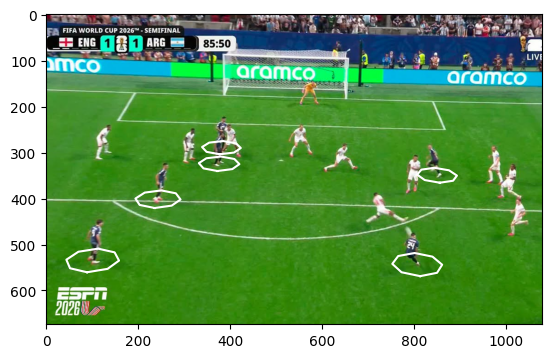

In [18]:
#b
pos_jugadores_img= np.array([[381,289],[376,324],[243,401],[101,534],[850,349],[807,543]])

coordenadas_jugadores= []
for (u,v) in pos_jugadores_img:
    coordenadas_jugadores.append(traducirPunto(Hinv,(u,v)))
coordenadas_jugadores= np.array(coordenadas_jugadores)

#genera un "circulo" de 1m de radio con centro en (x,y), se genera con 8 puntos(el 9 cierra el circulo)
def circulo(x,y):
    c=[]
    c.append((x+1, y))
    c.append((x+0.7, y+0.7))
    c.append((x, y+1))
    c.append((x-0.7, y+0.7))
    c.append((x-1, y))
    c.append((x-0.7, y-0.7))
    c.append((x, y-1))
    c.append((x+0.7, y-0.7))
    c.append((x+1, y))
    return c

#guardamos coordenadas de los circulos de cada jugador en el plano
circulos=[]
for (x,y) in coordenadas_jugadores:
    circulos.append(circulo(x,y))

#pasamos los circulos a la imagen
circulos_img=[]
for c in circulos:
    c_img=[]
    for (x,y) in c:
        c_img.append(traducirPunto(H1,(x,y)))
    circulos_img.append(np.array(c_img))

#dibujamos circulo
plt.imshow(mpimg.imread("futbol/test-gol-enzo.png"))
for c_img in circulos_img:
    plt.plot(c_img[:,0], c_img[:,1], c="white") #c_img[:,0]: todas las coordenadas u del circulo, c_img[:,1]: todas las coordenadas v del circulo.
plt.show()

Ejercicio C.
Primero, buscamos los pixeles de la parte mas cerca al arco del ultimo defensor (su pie). Pasamos esas coordenadas por H inversa para obtenerlas en metros. Como sabemos que las cancha mide 68 metros de ancho, sabemos que la linea a dibujar va a ir de y_inicial=0 a y_final=68, su x va a ser constante y va ser la x que obtuvimos al pasar las coordenadas del defensor por H inversa. Al ya obtener el punto incial y el punto final, los traducimos ambos con H, y dibujamos una linea que vaya de un punto al otro.

90.70691559191783 52.477701336147156


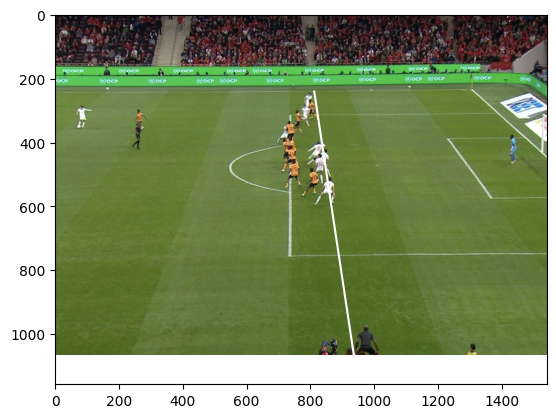

In [19]:
#c

#encontramos coordenadas del defensor en el plano, luego como sabemos que sobre el eje "y" la cancha mide 68m, la linea va a ir desde (x,0) a (x,68), siendo x donde este ubicado el defensor.
defensor= (825,326)
xd,yd =traducirPunto(H2inv,defensor)
xi,yi =traducirPunto(H2,(xd,0))
xf,yf =traducirPunto(H2,(xd,68))

print(xd,yd)
#dibujamos linea offside
plt.imshow(mpimg.imread("futbol/test-fuera-de-juego.png"))
plt.plot([xi,xf], [yi,yf], c="white")
plt.show()


### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad (a)

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

En un principio la idea era usar el ejercicio 2 para calcular los parámetros intrinsecos de la cámara, porque en el enunciado nos dice que, tenemos puntos en el plano Z = 0 y puntos en el plano Z = 0.1.

Pero  en base a lo calculado en el ejercicio 1, encontramos que para poder tener solución única necesitamos por lo menos 6 puntos, y en este dataset tenemos menos, por lo tanto lo que hicimos fue:

Asumir cierto error al calcular los parámetros y aplanar todo como si tuvieramos un plano único y usar el algoritmo con puntos coplanares

In [20]:
import pandas as pd
#Cargo el dataset
data = pd.read_csv('salguero/world_img_pts.csv', delimiter=';')

# Coordenadas del mundo real de cada punto, en metros
X = np.array(data['X'])
Y = np.array(data['Y'])
Z = np.array(data['Z'])

# Coordenadas de cada punto en la imagen de cada vista, en pixeles
U0 = np.array(data['u_0'])
V0 = np.array(data['v_0'])
U1 = np.array(data['u_1'])
V1 = np.array(data['v_1'])
U2 = np.array(data['u_2'])
V2 = np.array(data['v_2'])
U3 = np.array(data['u_3'])
V3 = np.array(data['v_3'])


obtpts = np.column_stack((X,Y))
imgPts0 = np.column_stack((U0,V0))
imgPts1 = np.column_stack((U1,V1))
imgPts2 = np.column_stack((U2,V2))
imgPts3 = np.column_stack((U3,V3))

print("X =", X)
print("Y =", Y)
print("Z =", Z)
print("vista 0: u =", U0, " v =", V0)
print("vista 1: u =", U1, " v =", V1)
print("vista 2: u =", U2, " v =", V2)
print("vista 3: u =", U3, " v =", V3)
#Calculo Qi a partir de cada una de las vistas
Q0 = obtenerQ2d(imgPts0,obtpts)
Q1 = obtenerQ2d(imgPts1,obtpts)
Q2 = obtenerQ2d(imgPts2,obtpts)
Q3 = obtenerQ2d(imgPts3,obtpts)

#Busco el que minimice y armo las H
vmin0 = encontrar_vector_minimo(Q0)
vmin1 = encontrar_vector_minimo(Q1)
vmin2 = encontrar_vector_minimo(Q2)
vmin3 = encontrar_vector_minimo(Q3)

Hmin0 = vmin0.reshape(3, 3)
Hmin1 = vmin1.reshape(3, 3)
Hmin2 = vmin2.reshape(3, 3)
Hmin3 = vmin3.reshape(3, 3)
#Genero A a partir de las Hmin
A = armarA([Hmin0, Hmin1, Hmin2, Hmin3])
#calculo los parámetros de K
K = calcularK2D(A)
K


X = [-4.   4.   6.5 -5.  -5. ]
Y = [ 3  0  3 14 76]
Z = [0.  0.  0.1 0.1 0.1]
vista 0: u = [ 281  889 1139  418  833]  v = [474 521 493 385 262]
vista 1: u = [ 255 1071 1403  437  997]  v = [490 577 550 377 227]
vista 2: u = [ 469 1147 1425  627 1094]  v = [581 653 625 485 357]
vista 3: u = [ 446 1118 1396  600 1064]  v = [563 621 590 466 331]


array([[2.78278008e+03, 1.35536578e+03, 2.89090323e+02],
       [0.00000000e+00, 2.13055733e+02, 1.95627005e+02],
       [0.00000000e+00, 0.00000000e+00, 1.00000000e+00]])

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad (b)


In [21]:
datos = np.loadtxt('salguero/gs_10_09_point_correspondences_v5.txt')
# el dataset tiene 6 filas con 51 puntos, esta muy mal representado, la primera fila es el indice
# la segunda x, tercera y cuarta z, quinta u y sexta v, lo ideal es trasponerla para ver mejor los datos
puntos = traspuesta(datos)
objPts = puntos[:, 1:4]       # (51, 3) X Y Z  ->  puntos[:, 1:3] para obtenerQ2d
imgPts = puntos[:, 4:6]       # (51, 2) u v
objPts


array([[  9.  ,  21.  ,   0.  ],
       [ -6.  ,  76.  ,   0.  ],
       [  5.  ,   3.  ,   0.  ],
       [ -4.  ,   0.  ,   0.  ],
       [ -3.5 ,   0.  ,   0.  ],
       [ -4.  ,   3.  ,   0.  ],
       [ -3.5 ,   3.  ,   0.  ],
       [ -3.  ,   0.  ,   0.  ],
       [ -2.5 ,   0.  ,   0.  ],
       [ -3.  ,   3.  ,   0.  ],
       [ -2.5 ,   3.  ,   0.  ],
       [ -2.  ,   0.  ,   0.  ],
       [ -1.5 ,   0.  ,   0.  ],
       [ -2.  ,   3.  ,   0.  ],
       [ -1.5 ,   3.  ,   0.  ],
       [ -1.  ,   0.  ,   0.  ],
       [ -0.5 ,   0.  ,   0.  ],
       [ -1.  ,   3.  ,   0.  ],
       [ -0.5 ,   3.  ,   0.  ],
       [  0.  ,   0.  ,   0.  ],
       [  0.5 ,   0.  ,   0.  ],
       [  0.  ,   3.  ,   0.  ],
       [  0.5 ,   3.  ,   0.  ],
       [  1.  ,   0.  ,   0.  ],
       [  1.7 ,   0.  ,   0.  ],
       [  1.  ,   3.  ,   0.  ],
       [  1.7 ,   3.  ,   0.  ],
       [  2.2 ,   0.  ,   0.  ],
       [  2.7 ,   0.  ,   0.  ],
       [  2.2 ,   3.  ,   0.  ],
       [  

In [22]:
Q_ejercicio_b = obtenerQ2d(imgPts,objPts)
vmin_ejercicio_b = encontrar_vector_minimo(Q_ejercicio_b)
Hminejercicio_b = vmin_ejercicio_b.reshape(3, 3)
Hminejercicio_b


array([[-1.09929427e-01, -6.30374504e-02, -7.03154295e-01],
       [ 1.43379161e-03, -1.05156377e-02, -6.99572246e-01],
       [ 9.18368531e-06, -5.74392725e-05, -1.36862954e-03]])

In [23]:
pose = obtenerPose2D(Hminejercicio_b,K)
#pose es la pose de la cámara.
pose



(array([[ 0.97332984,  0.22778923,  0.02722313],
        [ 0.04182274, -0.0595125 , -0.99735105],
        [-0.22556571,  0.97189008, -0.06745206]]),
 array([-21.53276373,  49.7825377 ,  33.61568764]))

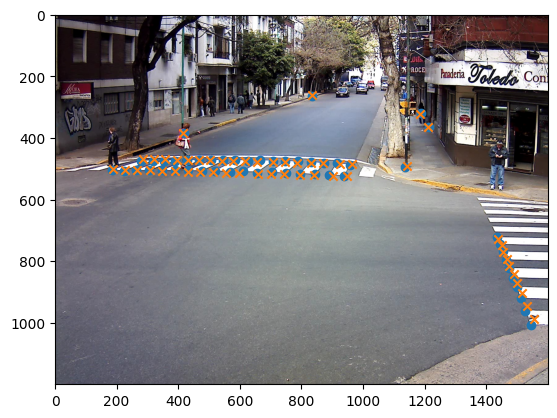

In [24]:
def mostrarPuntos(H, objPts, imgPts, imagen):
    plt.imshow(mpimg.imread(imagen))
    objPts_traducida=[]
    for (x,y) in objPts:
       objPts_traducida.append(traducirPunto(H,(x,y)))
    objPts_traducida=np.array(objPts_traducida)
    plt.scatter(imgPts[:, 0], imgPts[:, 1])
    plt.scatter(objPts_traducida[:, 0], objPts_traducida[:, 1], marker="x")
    plt.show()

objPts2d = puntos[:, 1:3] 
    
mostrarPuntos(Hminejercicio_b, objPts2d, imgPts, "salguero/img_10_18_47_351.jpg")

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad (b)

In [25]:
dataset = pd.read_csv('trayectoria_ejercicio_5/dataset.csv')
uvSeniora = np.column_stack((dataset['u_senora'],dataset['v_senora']))
uvTaxi = np.column_stack((dataset['u_taxi'],dataset['v_taxi']))
uvAutoGris = np.column_stack((dataset['u_auto_gris'],dataset['v_auto_gris']))
dataset

,timestamp,u_senora,v_senora,u_taxi,v_taxi,u_auto_gris,v_auto_gris
0,0.000,418.8,503.4,934.4,271.7,996.3,261.2
1,0.110,430.1,503.2,932.7,272.4,995.9,261.7
2,0.203,454.0,503.4,927.2,274.9,995.5,263.7
3,0.328,467.6,501.8,923.3,276.4,996.8,263.8
4,0.484,477.6,500.5,921.3,276.9,993.9,266.4
5,0.531,502.6,501.4,917.4,278.2,996.2,267.5
6,0.671,515.4,500.7,912.9,280.1,992.5,269.0
7,0.812,519.1,501.2,910.9,281.8,991.6,269.9
8,0.858,534.4,498.7,906.1,283.5,990.7,271.6
9,0.999,545.1,499.8,903.2,284.1,989.8,272.7


In [26]:
H_inv = inversa(Hminejercicio_b)

# Paso cada (u, v) de la imagen a (X, Y) en la calle (Z = 0), en metros, y lo agrego al dataset como columnas

# Señora
X_seniora = []
Y_seniora = []
for (u, v) in uvSeniora:
    XY = traducirPunto(H_inv, (u, v))
    X_seniora.append(XY[0])
    Y_seniora.append(XY[1])
dataset['X_seniora'] = X_seniora
dataset['Y_seniora'] = Y_seniora

# Taxi (auto negro/blanco)
X_taxi = []
Y_taxi = []
for (u, v) in uvTaxi:
    XY = traducirPunto(H_inv, (u, v))
    X_taxi.append(XY[0])
    Y_taxi.append(XY[1])
dataset['X_taxi'] = X_taxi
dataset['Y_taxi'] = Y_taxi

# Auto gris
X_auto_gris = []
Y_auto_gris = []
for (u, v) in uvAutoGris:
    XY = traducirPunto(H_inv, (u, v))
    X_auto_gris.append(XY[0])
    Y_auto_gris.append(XY[1])
dataset['X_auto_gris'] = X_auto_gris
dataset['Y_auto_gris'] = Y_auto_gris
dataset["X_seniora_diff"] = dataset["X_seniora"].diff()
dataset["Y_seniora_diff"] = dataset["Y_seniora"].diff()
dataset["X_taxi_diff"] = dataset["X_taxi"].diff()
dataset["Y_taxi_diff"] = dataset["Y_taxi"].diff()
dataset["X_auto_gris_diff"] = dataset["X_auto_gris"].diff()
dataset["Y_auto_gris_diff"] = dataset["Y_auto_gris"].diff()
dataset["dt"] = dataset["timestamp"].diff()
dataset["distancia_senora"] = np.sqrt((dataset["X_seniora_diff"]**2) + (dataset["Y_seniora_diff"]**2))
dataset["velocidad_senora"] = dataset["distancia_senora"] / dataset["dt"]
dataset["distancia_taxi"] = np.sqrt((dataset["X_taxi_diff"]**2) + (dataset["Y_taxi_diff"]**2))
dataset["velocidad_taxi"] = dataset["distancia_taxi"] / dataset["dt"]
dataset["distancia_auto_gris"] = np.sqrt((dataset["X_auto_gris_diff"]**2) + (dataset["Y_auto_gris_diff"]**2))
dataset["velocidad_auto_gris"] = dataset["distancia_auto_gris"] / dataset["dt"]
dataset

,timestamp,u_senora,v_senora,u_taxi,v_taxi,u_auto_gris,v_auto_gris,X_seniora,Y_seniora,X_taxi,...,Y_taxi_diff,X_auto_gris_diff,Y_auto_gris_diff,dt,distancia_senora,velocidad_senora,distancia_taxi,velocidad_taxi,distancia_auto_gris,velocidad_auto_gris
0,0.000,418.8,503.4,934.4,271.7,996.3,261.2,-1.264711,0.357113,-0.226369,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.110,430.1,503.2,932.7,272.4,995.9,261.7,-1.138226,0.394274,-0.243562,...,-0.694698,0.011755,-0.634403,0.110,0.131831,1.198466,0.694911,6.317374,0.634512,5.768291
2,0.203,454.0,503.4,927.2,274.9,995.5,263.7,-0.855545,0.428036,-0.279631,...,-2.389708,0.101162,-2.447145,0.093,0.284689,3.061176,2.389980,25.698706,2.449235,26.335856
3,0.328,467.6,501.8,923.3,276.4,996.8,263.8,-0.734177,0.571531,-0.324302,...,-1.377264,0.066014,-0.106154,0.125,0.187939,1.503508,1.377988,11.023905,0.125006,1.000047
4,0.484,477.6,500.5,921.3,276.9,993.9,266.4,-0.646975,0.687062,-0.366676,...,-0.455009,0.015339,-3.021601,0.156,0.144747,0.927866,0.456978,2.929345,3.021640,19.369489
5,0.531,502.6,501.4,917.4,278.2,996.2,267.5,-0.333794,0.671772,-0.423834,...,-1.150094,0.162295,-1.189436,0.047,0.313554,6.671353,1.151513,24.500287,1.200458,25.541651
6,0.671,515.4,500.7,912.9,280.1,992.5,269.0,-0.198959,0.749270,-0.458532,...,-1.615931,-0.082661,-1.635654,0.140,0.155520,1.110857,1.616304,11.545026,1.637741,11.698150
7,0.812,519.1,501.2,910.9,281.8,991.6,269.9,-0.144875,0.719972,-0.411969,...,-1.377497,0.008580,-0.942295,0.141,0.061509,0.436236,1.378284,9.775062,0.942335,6.683224
8,0.858,534.4,498.7,906.1,283.5,990.7,271.6,-0.017861,0.936632,-0.470869,...,-1.351996,0.049499,-1.720597,0.046,0.251145,5.459675,1.353278,29.419089,1.721309,37.419756
9,0.999,545.1,499.8,903.2,284.1,989.8,272.7,0.131183,0.876473,-0.535654,...,-0.475298,0.017786,-1.081348,0.141,0.160727,1.139907,0.479693,3.402079,1.081494,7.670172


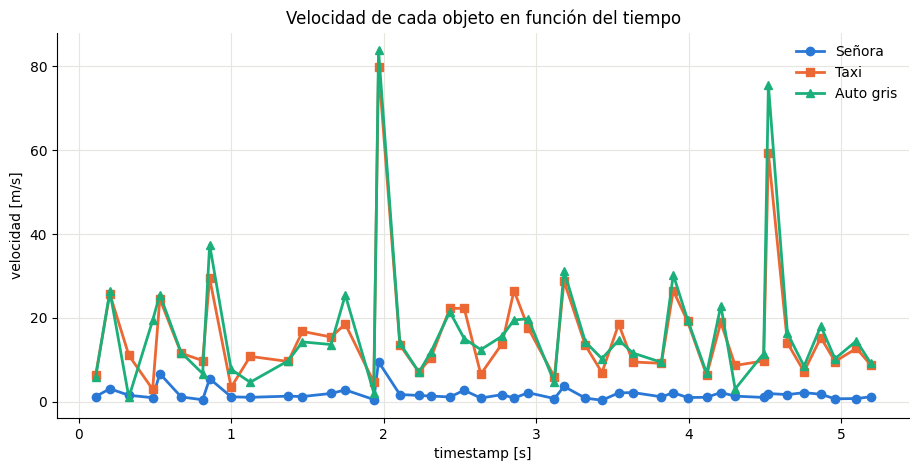

In [27]:
# Grafico la velocidad
series = [
    ("velocidad_senora", "Señora", "#2a78d6", "o"),
    ("velocidad_taxi", "Taxi", "#eb6834", "s"),
    ("velocidad_auto_gris", "Auto gris", "#1baf7a", "^"),
]

fig, ax = plt.subplots(figsize=(11, 5))
for columna, nombre, color, marcador in series:
    ax.plot(dataset["timestamp"], dataset[columna], color=color, linewidth=2,
            marker=marcador, markersize=6, label=nombre)

ax.set_xlabel("timestamp [s]")
ax.set_ylabel("velocidad [m/s]")
ax.set_title("Velocidad de cada objeto en función del tiempo")
ax.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

mirando el grafico hay picos muy altos, fui a revisar las fotografias y los puntos entre fotos consecutivos estan bien hechos pero el timestamp es muy corto para el movimiento que podria haberse realizado en ese punto por lo que se puede sugerir que el timestamp de la foto esta mal o se grabó de manera incorrecta por lo que voy a proceder a quitarlos

In [28]:
# Saco las filas 15 y 38. Los puntos están bien, pero el timestamp de esas dos fotos no se corresponde
# con el movimiento, el timestamp de la foto esta mal o se grabó de manera incorrecta
dataset_filtrado = dataset.drop(index=[15, 38])

dataset_filtrado["X_seniora_diff"] = dataset_filtrado["X_seniora"].diff()
dataset_filtrado["Y_seniora_diff"] = dataset_filtrado["Y_seniora"].diff()
dataset_filtrado["X_taxi_diff"] = dataset_filtrado["X_taxi"].diff()
dataset_filtrado["Y_taxi_diff"] = dataset_filtrado["Y_taxi"].diff()
dataset_filtrado["X_auto_gris_diff"] = dataset_filtrado["X_auto_gris"].diff()
dataset_filtrado["Y_auto_gris_diff"] = dataset_filtrado["Y_auto_gris"].diff()
dataset_filtrado["dt"] = dataset_filtrado["timestamp"].diff()
dataset_filtrado["distancia_senora"] = np.sqrt((dataset_filtrado["X_seniora_diff"]**2) + (dataset_filtrado["Y_seniora_diff"]**2))
dataset_filtrado["velocidad_senora"] = dataset_filtrado["distancia_senora"] / dataset_filtrado["dt"]
dataset_filtrado["distancia_taxi"] = np.sqrt((dataset_filtrado["X_taxi_diff"]**2) + (dataset_filtrado["Y_taxi_diff"]**2))
dataset_filtrado["velocidad_taxi"] = dataset_filtrado["distancia_taxi"] / dataset_filtrado["dt"]
dataset_filtrado["distancia_auto_gris"] = np.sqrt((dataset_filtrado["X_auto_gris_diff"]**2) + (dataset_filtrado["Y_auto_gris_diff"]**2))
dataset_filtrado["velocidad_auto_gris"] = dataset_filtrado["distancia_auto_gris"] / dataset_filtrado["dt"]

dataset_filtrado[["timestamp", "dt", "velocidad_senora", "velocidad_taxi", "velocidad_auto_gris"]]

,timestamp,dt,velocidad_senora,velocidad_taxi,velocidad_auto_gris
0,0.000,NaN,NaN,NaN,NaN
1,0.110,0.110,1.198466,6.317374,5.768291
2,0.203,0.093,3.061176,25.698706,26.335856
3,0.328,0.125,1.503508,11.023905,1.000047
4,0.484,0.156,0.927866,2.929345,19.369489
5,0.531,0.047,6.671353,24.500287,25.541651
6,0.671,0.140,1.110857,11.545026,11.698150
7,0.812,0.141,0.436236,9.775062,6.683224
8,0.858,0.046,5.459675,29.419089,37.419756
9,0.999,0.141,1.139907,3.402079,7.670172


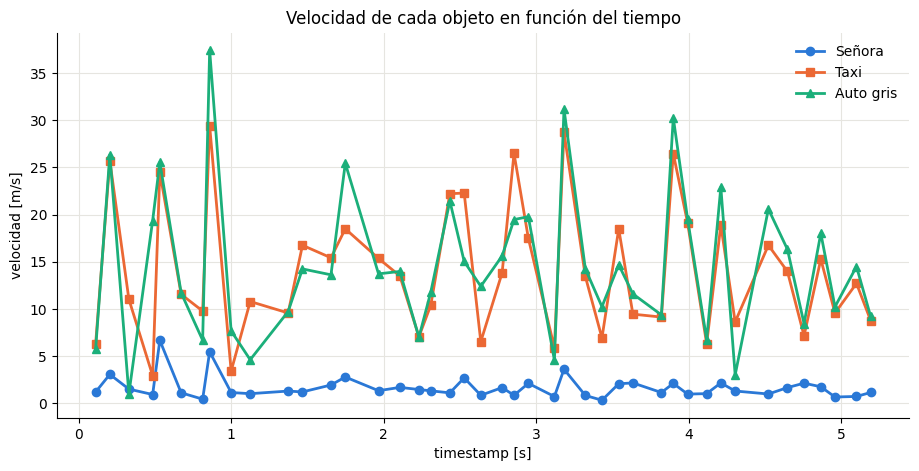

In [29]:
# Grafico la velocidad
series = [
    ("velocidad_senora", "Señora", "#2a78d6", "o"),
    ("velocidad_taxi", "Taxi", "#eb6834", "s"),
    ("velocidad_auto_gris", "Auto gris", "#1baf7a", "^"),
]

fig, ax = plt.subplots(figsize=(11, 5))
for columna, nombre, color, marcador in series:
    ax.plot(dataset_filtrado["timestamp"], dataset_filtrado[columna], color=color, linewidth=2,
            marker=marcador, markersize=6, label=nombre)

ax.set_xlabel("timestamp [s]")
ax.set_ylabel("velocidad [m/s]")
ax.set_title("Velocidad de cada objeto en función del tiempo")
ax.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

El archivo object_points me da las coordenadas de referencia es decir (U, V, W) y lo que me pide el ejercicio a) es que elegir las coordenadas de la imagen convenientemente. Como sabemos cuales son las de referencia entonces elijo los puntos que concuerdan con la referencia es decir el extremo exterior sup. izq., el extremo exterior sup. der., el extremo exterior inf. der. y el extremo exterior inf. izq.

### a)

In [ ]:

rgb = cv2.imread('heli/row_00248.png')
plt.imshow(rgb)
print(rgb.shape)

Con esto ya tenemos una referencia entonces jugamos un poco para ver que puntos puedo elegir, siguiendo el archivo chequeo_puntos_3d.ipynb y manteniendo el orden de object_points.csv.

In [ ]:
plt.imshow(rgb)

u_v = np.array([[525, 1005],
               [405, 1090],
               [395, 940],
               [640, 910],
               [655, 1060]])

M_0 = np.array([[0, 0, 0], 
                [-0.175, 0.3, 0], 
                [0.175, 0.3, 0],
                [0.175, -0.3, 0],
                [-0.175, -0.3, 0]])

plt.plot(u_v[:, 0], u_v[:, 1], 'ro', markersize = 2)

Usamos $\mathbf{C}^2 = \|\mathbf{J}_0\|_2 - \|\mathbf{I}_0\|_2 - 2i \times \mathbf{I}_0 \times \mathbf{J}_0$ para calcular las raices.

### b)

In [ ]:
def calculoLambdaMu(I0, J0):
    # Podemos usar el metodo sqrt de numpy que esta permitido    
    C_2 = norma(J0, 2) - norma(I0, 2) - 2j * producto_interno(I0, J0)
    
    raiz = np.sqrt(C_2) # me da una sola raiz pero el ejercicio me pide las dos
    
    lammbda, mu = raiz
    
    return (lammbda, mu), (-lammbda, -mu)

### c)

In [ ]:
def calcularSalidaPOSIT(Is, Js, fx, m0, M0):
    # Is y Js son vectores
    # M_0 = [X_0, Y_0, Z_0]
    
    norma_Is = norma(Is, 2)
    norma_Js = norma(Js, 2)
    
    Z_0 = fx / norma_Is
    
    i = Is / norma_Is
    j = Js / norma_Js
    
    # hace falta un vector ortogonal a i y j que ya son ortogonales entre si
    # para saber quien es k teniendo en cuenta los laboratorios
    # podemos pensar en el producto vectorial, pero no tenemos dicha funcion e implementarla
    # resulta engorroso porque no tememos funcion determinante. Hacerla directo con el producto
    # interno tambien es dificil porque no vimos como resolver un sistema lineal sin estar triangulado.
    # Entonces, uso QR_con_GS y me armo una matriz A con i, j y (1, 0, 0). Como i y j ya son ortogonales
    # en Q van a ser los mismos y la tercer columna va a ser nuestro i deseado. Justamente, la Q va a ser
    # R que nos estan pidiendo
    
    A = traspuesta(np.array([i,j,[1,0,0]]))
    
    Q, R_de_Q = QR_con_GS(A)
    
    k = Q[:, 2] 
    R = Q
    
    # Centramos las coordenadas de la imagen
    K = pd.read_csv('TP/heli/K.csv') 
    x_0 = m0[0] - K[0][2]
    y_0 = m0[1] - K[1][2]
    
    
    X_0 = (Z_0 / fx) * x_0
    Y_0 = (Z_0 / fx) * y_0
    
    # Trasladamos la camara para que M0 sea el origen
    T = np.array([X_0, Y_0, Z_0]) - arroba(R, M0)
    
    return i, j, k, Z_0, R, T 

### d)

In [ ]:
def evaluarPose(R, t, obj_vecs, img_vecs, K):
    validos = len(obj_vecs)
    puntos_camara = []
    
    for vecs in obj_vecs:
        punto_camara = arroba(R, vecs) + t # [X_i, Y_i, Z_i]
        # Quiere decir que quedo detras de la camara. Descartamos la solucion
        if punto_camara[2] <= 0: 
            return 0, None    
            
        puntos_camara.append(punto_camara)
     
    # Ahora queremos ver donde va a parar ese punto en el pixel (en la foto)
    # Las proyecciones en los pixeles van a ser K multiplicado cada punto
    # dada en la seccion del modelo pinhole ecuacion (2)
    
    fx = K[0][0]
    fy = K[1][1]
    se = K[0][1]
    cu = K[0][2]
    cv = K[1][2]
    
    for punto in puntos_camara:
        X_i, Y_i, Z_i = punto
        u = fx * (X_i / Z_i) + se * (Y_i / Z_i) + cu
        v = fy * (Y_i / Z_i) + cv
        proyecciones.append(np.array([u, v]))
        
    # Una vez que tenemos la proyecciones, calculamos el RMS
    proyecciones = np.array(proyecciones) 
    img_vecs = np.array(img_vecs)
    
    rms = np.sqrt(np.mean((img_vecs - proyecciones)**2))

    return validos, rms

### e)

In [ ]:
def aplicarPOSIT(obj_vecs, img_vecs, K, MaxIt, atol):
    # Devolvemos la pose de la camara R y t y vamos ajustando iterativamente
    
    M0 = obj_vecs[0]
    
    # Centralizamos los puntos de la imagen como en c)
    x_y = []
    for u, v in img_vecs:
        x = u - K[0][2]
        y = v - K[1][2]
        
        x_y.append([x, y])
    
    x_y = np.array(x_y) 
    
    A = []
    for i in range(len(obj_vecs)):
        A.append(obj_vecs[i] - M0)
        
    A = np.array(A)
    
    pseudo = pseudoinversa(A)
    
    e_i_k = np.zeros(len(obj_vecs))
    
    m0 = x_y[0]
    
    fx = K[0][0] # foco
    
    R = None
    t = None
    
    iteracion = 0

    # Iteracion POSIT
    while iteracion < MaxIt:
        # 1.
        b_u = []
        b_v = []
        
        for i in range(len(img_vecs)):
            x_i, y_i = x_y[i]
            
            b_i_u = x_i * (1 + e_i_k[i]) - m0[0] # numero
            b_i_v = y_i * (1 + e_i_k[i]) - m0[1] # numero
            
            b_u.append(b_i_u)
            b_v.append(b_i_v)
            
        b_u = np.array(b_u)
        b_v = np.array(b_v)
        
        # 2.  
        I0 = arroba(pseudo, b_u)
        J0 = arroba(pseudo, b_v)
        
        # 3.  
        r_1, r_2 = calculoLambdaMu(I0, J0)
        
        # 4.
        I_1 = I0 + r_1[0]
        J_1 = J0 + r_1[1]
        
        I_2 = I0 + r_2[0]
        J_2 = J0 + r_2[1]
        
        fx = K[0][0] # foco
        
        i_1, j_1, k_1, Z_0_1, R_1, t_1 = calcularSalidaPOSIT(I_1, J_1, fx, m0, M0)
        i_2, j_2, k_2, Z_0_2, R_2, t_2 = calcularSalidaPOSIT(I_2, J_2, fx, m0, M0)

        # 5.
        
        candidatos = []
        if Z_0_1 > 0:
            _, rms_1 = evaluarPose(R_1, t_1, obj_vecs, img_vecs, K)
            candidatos.append([rms_1, R_1, t_1, Z_0_1, k_1])
        if Z_0_2 > 0:
            _, rms_2 = evaluarPose(R_2, t_2, obj_vecs, img_vecs, K)
            candidatos.append([rms_2, R_2, t_2, Z_0_2, k_2])
        
        if len(candidatos) == 0:
            raise ValueError('No se encontro ninguna pose valida')  
        
        if rms_1 >= rms_2:
            rms, R, t, Z_0, k = candidatos[0]
        else:
            rms, R, t, Z_0, k = candidatos[1]
            
        e_i_k_1 = (1 / Z_0) * arroba(A, k) # vector
        # 6.

        if norma(e_i_k_1) - norma(e_i_k) < atol:
            return R, t
        
        e_i_k = e_i_k_1  
        
        iteracion += 1
        

    return R, t

---